# 05A — K-means : segmentation clients | Panier Vert

Chaque notebook lit **le même** `data/gold/user_segments.parquet` produit par le notebook 04. Les transformations (`log1p`, normalisation) et l'échantillon pseudo-aléatoire de 15 000 clients sont identiques : la comparaison est cohérente. Les résultats sont tracés dans `mlruns/` à la racine du projet ; aucune instance MLflow ne doit être lancée pour exécuter les notebooks. Pour afficher l'interface, depuis la racine : `mlflow ui --backend-store-uri ./mlruns`.

**Note méthodologique :** la normalisation est ajustée ici sur l'ensemble des clients avant l'échantillonnage, comme dans le notebook initial. Pour une évaluation hors échantillon stricte, il faudrait ajuster les transformations sur un jeu d'entraînement seulement. Les métriques internes de clustering ne garantissent pas à elles seules une segmentation utile métier.

## 1 — Chargement et préparation

In [1]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

cwd = Path.cwd()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "data" / "gold" / "user_segments.parquet").exists()), None)
if ROOT is None:
    raise FileNotFoundError("data/gold/user_segments.parquet introuvable : exécuter le notebook 04 ou adapter ROOT.")
GOLD = ROOT / "data" / "gold" / "user_segments.parquet"
REPORT_DIR = ROOT / "data" / "reports" / "segmentation"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri((ROOT / "mlruns").resolve().as_uri())

df = pd.read_parquet(GOLD).set_index("user_id")
print(f"{len(df):,} clients | {df.shape[1]} colonnes")

# Préparation identique pour les trois modèles
DROP = ["tenure_days", "nb_distinct_products", "product_diversity", "segment", "segment_name"]
feat = df.drop(columns=[c for c in DROP if c in df.columns]).select_dtypes(include=["number"]).copy()
if feat.empty:
    raise ValueError("Aucune variable numérique disponible après exclusion.")
if feat.isna().any().any():
    raise ValueError("Valeurs manquantes dans les variables : vérifier le notebook 04.")

X = feat.copy()
skewed = [c for c in X.columns if X[c].skew() > 1 and (X[c] >= 0).all()]
X[skewed] = np.log1p(X[skewed])
scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=X.columns)
K = int(df["segment"].nunique()) if "segment" in df.columns else 4
CMP_N = 15_000
rng = np.random.RandomState(RANDOM_STATE)
cmp_idx = rng.choice(len(Z), size=min(CMP_N, len(Z)), replace=False)
Zc = Z.iloc[cmp_idx].to_numpy()
print("Variables :", list(Z.columns))
print("Échantillon commun :", Zc.shape, "| K de référence :", K)

def segmentation_metrics(data, labels, *, exclude_noise=True):
    labels = np.asarray(labels)
    mask = (labels != -1) if exclude_noise else np.ones(len(labels), dtype=bool)
    unique = np.unique(labels[mask])
    out = {"n_clusters": int(len(unique)), "noise_pct": float(100 * (~mask).mean()),
           "classified_pct": float(100 * mask.mean())}
    if len(unique) >= 2 and mask.sum() > len(unique):
        # Silhouette sur un sous-échantillon pour éviter la matrice O(n²)
        out["silhouette"] = float(silhouette_score(data[mask], labels[mask],
            sample_size=min(2500, int(mask.sum())), random_state=RANDOM_STATE))
        out["davies_bouldin"] = float(davies_bouldin_score(data[mask], labels[mask]))
    else:
        out["silhouette"] = float("nan")
        out["davies_bouldin"] = float("nan")
    if mask.any():
        out["largest_cluster_pct"] = float(100 * pd.Series(labels[mask]).value_counts(normalize=True).iloc[0])
    return out

def log_numeric_metrics(d):
    for k, v in d.items():
        if isinstance(v, (int, float, np.integer, np.floating)) and np.isfinite(v):
            mlflow.log_metric(k, float(v))


206,209 clients | 19 colonnes
Variables : ['nb_orders', 'mean_gap_days', 'weekend_share', 'morning_share', 'evening_share', 'avg_basket_size', 'reorder_ratio', 'organic_share', 'share_produce', 'share_dairy_eggs', 'share_snacks', 'share_beverages', 'share_frozen', 'share_pantry']
Échantillon commun : (15000, 14) | K de référence : 4


## 2 — K-means sur l’échantillon commun

On reprend le nombre de groupes du notebook 04 pour comparer équitablement les méthodes.

In [2]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")

print("Serveur MLflow :", mlflow.get_tracking_uri())

Serveur MLflow : http://127.0.0.1:5000


2026/11/19 15:40:19 INFO mlflow.tracking.fluent: Experiment with name 'PanierVert_KMeans_Clients' does not exist. Creating a new experiment.


,n_clusters,noise_pct,classified_pct,silhouette,davies_bouldin,largest_cluster_pct,inertia,duration_s
0,4,0.0,100.0,0.096873,2.468926,29.573333,160241.146564,0.600711


,nb_orders,mean_gap_days,weekend_share,morning_share,evening_share,avg_basket_size,reorder_ratio,organic_share,share_produce,share_dairy_eggs,share_snacks,share_beverages,share_frozen,share_pantry
0,7.34,17.90,0.41,0.32,0.16,10.29,0.34,0.41,0.43,0.15,0.05,0.05,0.05,0.05
1,12.09,16.12,0.29,0.42,0.11,5.43,0.46,0.12,0.12,0.09,0.20,0.28,0.04,0.03
2,33.09,9.42,0.35,0.34,0.18,11.28,0.64,0.34,0.31,0.18,0.08,0.07,0.06,0.06
3,7.74,18.21,0.32,0.24,0.24,10.20,0.30,0.14,0.16,0.16,0.08,0.08,0.12,0.09


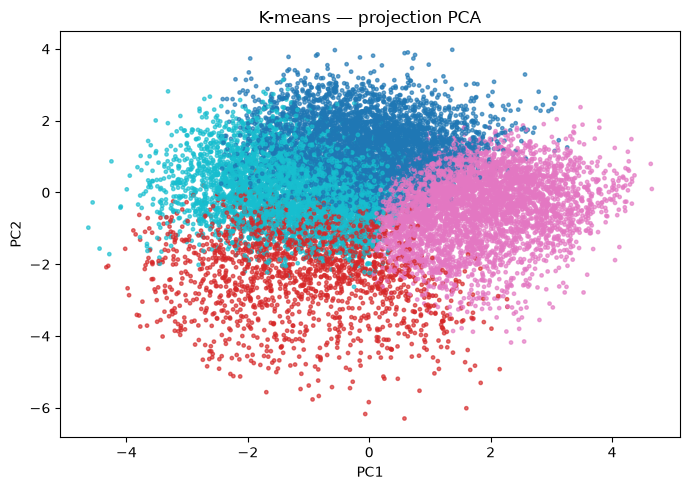

🏃 View run kmeans_k4_n15000 at: http://127.0.0.1:5000/#/experiments/1/runs/2179a1b2f67240d8a99a203fbfc8f3c4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [3]:
from sklearn.cluster import KMeans
mlflow.set_experiment("PanierVert_KMeans_Clients")
with mlflow.start_run(run_name=f"kmeans_k{K}_n{len(Zc)}"):
    t0 = time.perf_counter()
    model = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(Zc)
    duration = time.perf_counter() - t0
    scores = segmentation_metrics(Zc, labels)
    scores.update({"inertia": float(model.inertia_), "duration_s": duration})
    mlflow.log_params({"algorithm": "KMeans", "n_clusters": K, "n_init": 10,
                       "sample_size": len(Zc), "random_state": RANDOM_STATE})
    log_numeric_metrics(scores)
    display(pd.DataFrame([scores]))
    profile = feat.iloc[cmp_idx].groupby(labels).mean().round(2)
    display(profile)
    profile.to_csv(REPORT_DIR / "profil_kmeans_15k.csv")
    mlflow.log_artifact(str(REPORT_DIR / "profil_kmeans_15k.csv"))
    fig, ax = plt.subplots(figsize=(7, 5))
    xy = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Zc)
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab10", s=6, alpha=.65)
    ax.set(title="K-means — projection PCA", xlabel="PC1", ylabel="PC2")
    fig.tight_layout()
    fig.savefig(REPORT_DIR / "kmeans_pca.png", dpi=130)
    mlflow.log_artifact(str(REPORT_DIR / "kmeans_pca.png"))
    plt.show()

## 3 — Interprétation

Attribuer des noms métier aux segments **après** examen des profils (fréquence, panier moyen, fidélité). Ce notebook compare un K-means réentraîné sur l’échantillon commun ; les segments complets de référence restent dans `user_segments.parquet`.